# Triple momentum, ITEM and OGM with weights selected a posteriori

Companion notebook to the last paragraph of the proposed Section 5.6 (ITEM and the triple momentum method), in the format of `Section1_adaptive_A_v2.ipynb`: same data, preprocessing, constants and stopping rule. The numbers (5.28)–(5.36) and Algorithm 5.7 are those of the proposed subsection; the other numbers are those of the manuscript version of 22 November 2026.

**Pieces** ($q=m/L$). A query at $y_k$ gives the gradient step $x_{k+1}=y_k-\frac1L\nabla f(y_k)$, the point $w_k=y_k-\frac1m\nabla f(y_k)$, and the two bounds (5.32) on $f_\star$ at a minimizer, $C_k(x_\star)\le f_\star\le D_k(x_\star)$:
$$C_k(x)=f(y_k)-\tfrac1{2m}\|\nabla f(y_k)\|^2+\tfrac{m}{2(1-q)}\|x-w_k\|^2,\qquad D_k(x)=f(y_k)-\tfrac1{2L}\|\nabla f(y_k)\|^2-\tfrac{m}{2(1-q)}\|x-x_{k+1}\|^2 .$$

**Triple momentum with optimal quadratic averaging** ($m>0$, no regularization; Algorithm 5.7). The state is $x_k$ and a convex combination $v_k+\frac{m}{2(1-q)}\|\cdot-c_k\|^2$ of the pieces $C_0,\ldots,C_{k-1}$. One iteration: $y_k=x_k+\frac{\sqrt q}{1+\sqrt q}(c_k-x_k)$, then the new piece $C_k$ enters with a weight $\lambda_k$,
$$c_{k+1}=(1-\lambda_k)\,c_k+\lambda_k\,w_k,\qquad v_{k+1}=(1-\lambda_k)\,v_k+\lambda_k\big(f(y_k)-\tfrac1{2m}\|\nabla f(y_k)\|^2\big)+\tfrac{m}{2(1-q)}\lambda_k(1-\lambda_k)\|c_k-w_k\|^2 .$$
The minimizer lies in the ball centered at $z_{k+1}=\frac12(x_{k+1}+c_{k+1})$ with squared radius $R_{k+1}^2=\frac{1-q}{m}\big(f(y_k)-\frac1{2L}\|\nabla f(y_k)\|^2-v_{k+1}\big)-\frac14\|x_{k+1}-c_{k+1}\|^2$, which is computable.

- *Triple momentum* (5.35): $\lambda_k=1-(1-\sqrt q)^2$, for which $R_{k+1}^2\le(1-\sqrt q)^2R_k^2$.
- *Optimal quadratic averaging* (5.36): the weight in $[0,1]$ giving the smallest ball (the squared radius is a convex quadratic in $\lambda$),
$$\lambda_k=\mathrm{Proj}_{[0,1]}\bigg\{\frac{(1-q)\big(2\,(f(y_k)-v_k)-\langle\nabla f(y_k),\,y_k-c_k\rangle\big)}{m\,\|w_k-c_k\|^2}\bigg\},$$
so that again $R_{k+1}^2\le(1-\sqrt q)^2R_k^2$, whatever the previous weights.

**ITEM and OGM with one aggregate** ($m\ge0$, with regularization). The state is $x_k$, an aggregate $W_k$ of the pieces $C_0,\ldots,C_{k-1}$ and a weight $A_k$. The step is that of ITEM (5.28) from the weight $A_k$, which is OGM (5.10) when $m=0$. Then, exactly as in (4.29)–(4.32), with
$$t=\frac{(1-q)A}{1+2qA},\qquad e_\lambda=W_\lambda(x_0)-D(x_0),\qquad \bar g_\lambda=\nabla W_\lambda(x_0)-\nabla D(x_0),\qquad W_\lambda=(1-\lambda)W_k+\lambda C_k,$$
the certificate reads $e_\lambda-\frac t{2L}\|\bar g_\lambda\|^2\ge0$, and the largest certified weight is $t_{k+1}=2L\max_{\lambda\in[0,1]}e_\lambda/\|\bar g_\lambda\|^2$ (closed form (4.32)), with $A_{k+1}=\frac{t_{k+1}}{1-q-2qt_{k+1}}$ and $z_{k+1}=x_0-\frac{t_{k+1}}{L}\bar g_{\lambda_k}$. The upper piece $D$ is the new one, $D_k$, or the previous one when it certifies a larger weight; $x_{k+1}$ is then the corresponding gradient step. When $m=0$ the upper pieces are constants, and this amounts to keeping the smallest value so far, as in SPGM (5.20). Guarantees: $\|z_k-x_\star\|^2\le\|x_0-x_\star\|^2/(1+2qA_k)$, and $f(x_k)-f_\star\le L\|x_0-x_\star\|^2/(2A_k)$ when $m=0$.

**Nesterov's method (2.25) and Algorithm 4.12** are run by the same functions, for comparison: pieces $\ell_i$ (4.1), upper value $f(x_{k+1})$, $t=A/(1+qA)$. For Algorithm 4.12 this is `two_variable` of `Section1_adaptive_A_v2.ipynb`, with the same arithmetic. The option of keeping the smallest value $f(x_i)$ so far (Section 4.6) is also run.

**Stopping and round-off.** All accelerated runs stop when $\|\nabla f(y_k)\|\le10^{-7}\|\nabla f(y_0)\|$ (the last value is then repeated in the plots). The certificates are differences of function values. Optimal quadratic averaging uses the weight (5.36) while the gap $\frac{m}{1-q}R_k^2$ is above $10^{-10}\max\{1,|f(y_0)|\}$, and the weight of (5.35) afterwards. The rules with regularization use the a priori weight whenever the computed one is smaller, which can only come from round-off, and the tables count these steps. The weight $A$ is recovered from $t$ through $1+2qA=(1-q)/(1-q-2qt)$, which amplifies the relative round-off of $t$ by $1+2qA$: the bound on $\|z_k-x_\star\|^2$ is checked while $1+2qA_k<10^9$, and the last section looks at it in extended precision.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import expit, logsumexp, softmax
from sklearn.datasets import load_diabetes

SONAR_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/undocumented/connectionist-bench/sonar/sonar.all-data"
SONAR_FILE = "sonar.csv" if os.path.exists("sonar.csv") else SONAR_URL
_ = np.seterr(divide="ignore", invalid="ignore")

## Problems

As in `Section1_adaptive_A_v2.ipynb`. Top row of the figure: the three problems of Section 1, methods run with $m=0$. Bottom row: methods run with the true $m>0$ (a ridge term $\frac12\|x\|^2$ is added to the smoothed $\ell_\infty$ problem, which has $m=0$).

In [2]:
def standardize(X):
    return (X - X.mean(axis=0)) / X.std(axis=0)


def add_intercept(Z):
    return np.hstack([Z, np.ones((Z.shape[0], 1))])


def solve_with_newton(f, grad, hess, x0):
    x = minimize(f, x0, jac=grad, hess=hess, method="trust-exact", options={"gtol": 1e-13, "maxiter": 1000}).x
    for _ in range(3):                                   # plain Newton steps: the distances to x_star are measured below
        x = x - np.linalg.solve(hess(x), grad(x))
    return x


diabetes = load_diabetes(scaled=False)
A_diabetes = add_intercept(standardize(diabetes.data))
b_diabetes = standardize(diabetes.target)

sonar = pd.read_csv(SONAR_FILE, header=None)
A_sonar = add_intercept(standardize(sonar.iloc[:, :60].to_numpy(dtype=float)))
y_sonar = np.where(sonar.iloc[:, 60] == "M", 1.0, -1.0)


def least_squares(ridge, n_iter):
    A, b = A_diabetes, b_diabetes
    n, d = A.shape
    f = lambda x: np.sum((A @ x - b) ** 2) / (2 * n) + ridge / 2 * x @ x
    grad = lambda x: A.T @ (A @ x - b) / n + ridge * x
    ev = np.linalg.eigvalsh(A.T @ A / n)
    x_star = np.linalg.solve(A.T @ A / n + ridge * np.eye(d), A.T @ b / n)
    return dict(f=f, grad=grad, L=ev[-1] + ridge, m=ev[0] + ridge, x0=np.zeros(d), x_star=x_star, n_iter=n_iter)


def logistic(ridge, n_iter):
    A, y = A_sonar, y_sonar
    n, d = A.shape
    lam = 1 / n + ridge
    f = lambda x: np.mean(np.logaddexp(0, -y * (A @ x))) + lam / 2 * x @ x
    grad = lambda x: -A.T @ (y * expit(-y * (A @ x))) / n + lam * x
    def hess(x):
        s = expit(A @ x)
        return A.T @ (A * (s * (1 - s))[:, None]) / n + lam * np.eye(d)
    L = np.linalg.eigvalsh(A.T @ A)[-1] / (4 * n) + lam
    return dict(f=f, grad=grad, L=L, m=lam, x0=np.zeros(d), x_star=solve_with_newton(f, grad, hess, np.zeros(d)), n_iter=n_iter)


def smoothed_linf(ridge, n_iter, tau=0.02):
    A, b = A_diabetes, b_diabetes
    n, d = A.shape
    A2, b2 = np.vstack([A, -A]), np.concatenate([b, -b])
    f = lambda x: tau * logsumexp((A2 @ x - b2) / tau) + ridge / 2 * x @ x
    grad = lambda x: A2.T @ softmax((A2 @ x - b2) / tau) + ridge * x
    def hess(x):
        p = softmax((A2 @ x - b2) / tau)
        Ap = A2.T @ p
        return (A2.T @ (A2 * p[:, None]) - np.outer(Ap, Ap)) / tau + ridge * np.eye(d)
    L = np.max(np.sum(A ** 2, axis=1)) / tau + ridge
    return dict(f=f, grad=grad, L=L, m=ridge, x0=np.zeros(d), x_star=solve_with_newton(f, grad, hess, np.zeros(d)), n_iter=n_iter)

runs = {   # name: (problem, value of m given to the methods)
    "Least squares, $m=0$ used": (least_squares(0.0, 1000), 0.0),
    "Logistic regression, $m=0$ used": (logistic(0.0, 1000), 0.0),
    r"Smoothed $\ell_\infty$, $m=0$": (smoothed_linf(0.0, 3000), 0.0),
    "Least squares, $m>0$ used": (least_squares(0.0, 600), None),
    "Logistic regression, $m>0$ used": (logistic(0.0, 600), None),
    r"Smoothed $\ell_\infty$ + ridge 1": (smoothed_linf(1.0, 1200), None),
}
for name, (P, m_used) in runs.items():
    print(f"{name:40s} L = {P['L']:.4g}, m = {P['m']:.3g}, m given to the methods = {P['m'] if m_used is None else m_used:.3g}")

Least squares, $m=0$ used                L = 4.024, m = 0.00856, m given to the methods = 0
Logistic regression, $m=0$ used          L = 3.057, m = 0.00481, m given to the methods = 0
Smoothed $\ell_\infty$, $m=0$            L = 2489, m = 0, m given to the methods = 0
Least squares, $m>0$ used                L = 4.024, m = 0.00856, m given to the methods = 0.00856
Logistic regression, $m>0$ used          L = 3.057, m = 0.00481, m given to the methods = 0.00481
Smoothed $\ell_\infty$ + ridge 1         L = 2490, m = 1, m given to the methods = 1


## Methods

In [3]:
def gd(f, grad, x0, alpha, n_iter):
    x = x0.copy(); values = [f(x)]
    for k in range(n_iter):
        x = x - alpha * grad(x); values.append(f(x))
    return np.array(values)


def parameters(rule, q):
    # rule="nesterov": Nesterov's method (2.25), with t = A/(1+qA).
    # rule="item":     ITEM (5.28), that is, OGM (5.10) when m = 0, with t = (1-q)A/(1+2qA).
    if rule == "nesterov":
        increment = lambda A: (1 + 2 * q * A + np.sqrt(1 + 4 * A + 4 * q * A * A)) / (2 * (1 - q))
        coupling = lambda A, a: a * (1 + q * A) / (A + a + 2 * q * A * a + q * A * A)
        delta = lambda A, a: a / (1 + q * (A + a))
        to_t, to_A = (lambda A: A / (1 + q * A)), (lambda t: t / (1 - q * t))
    else:
        increment = lambda A: (1 + q * (3 - q) * A + np.sqrt((1 + 2 * A) * (1 + 2 * q * A))) / (1 - q) ** 2
        coupling = lambda A, a: 1 - A / ((1 - q) * (A + a))
        delta = lambda A, a: (a + q * (A + a)) / (1 + 2 * q * (A + a))
        to_t, to_A = (lambda A: (1 - q) * A / (1 + 2 * q * A)), (lambda t: t / (1 - q - 2 * q * t))
    return increment, coupling, delta, to_t, to_A


def accelerated(f, grad, x0, x_star, L, m, n_iter, rule, tol=1e-7):
    # The methods with a priori weights: z_{k+1} = z_k + q delta_k (y_k - z_k) - delta_k/L grad f(y_k) in both cases.
    q = m / L
    increment, coupling, delta, _, _ = parameters(rule, q)
    x, z, A = x0.copy(), x0.copy(), 0.0
    h = dict(f=[f(x0)], A=[0.0], dist2=[np.sum((x0 - x_star) ** 2)])
    for k in range(n_iter):
        a = increment(A); tau, dlt = coupling(A, a), delta(A, a)
        y = x + tau * (z - x)
        g = grad(y); g2 = g @ g
        if k == 0: g2_0 = g2
        if g2 <= tol ** 2 * g2_0: break
        x, z, A = y - g / L, z + q * dlt * (y - z) - dlt / L * g, A + a
        h["f"].append(f(x)); h["A"].append(A); h["dist2"].append(np.sum((z - x_star) ** 2))
    return {key: np.array(v) for key, v in h.items()}


def best_weight(e0, e1, d0, d1, L):
    # max over lam in [0,1] of 2L ((1-lam) e0 + lam e1) / ||(1-lam) d0 + lam d1||^2: candidates 0, 1 and lam_+, lam_- of (4.32)
    S = lambda lam: 2 * L * ((1 - lam) * e0 + lam * e1) / np.sum(((1 - lam) * d0 + lam * d1) ** 2)
    cands = [0.0, 1.0]
    if e1 != e0:
        r = np.linalg.norm(e0 * d1 - e1 * d0) / np.linalg.norm(d1 - d0)
        cands += [lam for lam in ((-e0 + r) / (e1 - e0), (-e0 - r) / (e1 - e0)) if 0.0 < lam < 1.0]
    vals = [S(lam) for lam in cands]
    i = int(np.argmax(vals))
    return vals[i], cands[i], S


def grid_max(e0, e1, d0, d1, L, lam=np.linspace(0, 1, 401)[:, None]):
    # the same ratio on a grid of 401 weights (check of the closed form)
    return np.max(2 * L * ((1 - lam) * e0 + lam * e1)[:, 0] / np.sum(((1 - lam) * d0 + lam * d1) ** 2, axis=1))


def one_aggregate(f, grad, x0, x_star, L, m, n_iter, rule, upper="last", tol=1e-7):
    # One aggregate W of the lower pieces, and the largest weight certified by W and the new piece, (4.31)-(4.32).
    # rule="nesterov": Algorithm 4.12; pieces ell_i (4.1), upper value f(x_{k+1}).
    # rule="item":     ITEM / OGM with one aggregate; pieces C_i and D_i (5.32).
    # upper="best": the previous upper piece (and its point) is kept when it certifies a larger weight; when the upper
    # pieces are values (rule="nesterov", or m = 0), this is the smallest value so far.
    q = m / L; mt = m / (1 - q)
    increment, coupling, _, to_t, to_A = parameters(rule, q)
    x, z, t, W = x0.copy(), x0.copy(), 0.0, None
    h = dict(f=[f(x0)], A=[0.0], dist2=[np.sum((x0 - x_star) ** 2)], ratio=[], lam=[], kept=[], below=[], grid_excess=[], tight=[])
    for k in range(n_iter):
        A = to_A(t)
        a = increment(A); tau = coupling(A, a)
        y = x + tau * (z - x)
        g = grad(y); g2 = g @ g
        if k == 0: g2_0 = g2
        if g2 <= tol ** 2 * g2_0: break
        fy, x_new = f(y), y - g / L
        fx_new = f(x_new)
        if rule == "nesterov":      # value and gradient at x0 of the new lower piece ell_k, and of the upper value f(x_{k+1})
            Q, GQ = fy + g @ (x0 - y) + m / 2 * np.sum((x0 - y) ** 2), g + m * (x0 - y)
            U_new, GU_new = fx_new, 0.0
        else:                       # value and gradient at x0 of the new pieces C_k and D_k
            Q, GQ = fy + g @ (x0 - y) + g2 / (2 * L) + mt / 2 * np.sum((x0 - x_new) ** 2), g + mt * (x0 - x_new)
            U_new, GU_new = fy - g2 / (2 * L) - mt / 2 * np.sum((x0 - x_new) ** 2), mt * (x_new - x0)
        if W is None:               # first query: a single piece
            lam, d = 1.0, GQ - GU_new
            t_new = 2 * L * (Q - U_new) / (d @ d)
        else:
            t_new, lam, _ = best_weight(W - U_new, Q - U_new, GW - GU_new, GQ - GU_new, L)
            h["grid_excess"].append(grid_max(W - U_new, Q - U_new, GW - GU_new, GQ - GU_new, L) / t_new - 1)
            keep = False
            if upper == "best":
                t_old, lam_old, _ = best_weight(W - U, Q - U, GW - GU, GQ - GU, L)
                if t_old > t_new: keep, t_new, lam = True, t_old, lam_old
            t_prior = to_t(A + a)   # the a priori weight is certified: a smaller t_new can only come from round-off
            h["below"].append(t_new < t_prior)
            if t_new < t_prior: keep, t_new, lam = False, t_prior, a / (A + a)
            if keep: U_new, GU_new, x_new, fx_new = U, GU, x, h["f"][-1]
            h["lam"].append(lam); h["kept"].append(keep)
        W, GW = (Q, GQ) if W is None else ((1 - lam) * W + lam * Q, (1 - lam) * GW + lam * GQ)
        U, GU = U_new, GU_new
        e, d = W - U, GW - GU
        if k > 0: h["tight"].append((e - t_new / (2 * L) * (d @ d)) / abs(e))        # certificate: zero at the selected pair
        h["ratio"].append((to_A(t_new) - A) / a)
        x, z, t = x_new, x0 - t_new / L * d, t_new
        h["f"].append(fx_new); h["A"].append(to_A(t_new)); h["dist2"].append(np.sum((z - x_star) ** 2))
    return {key: np.array(v) for key, v in h.items()}


def triple_momentum(f, grad, x0, x_star, L, m, n_iter, oqa=False, tol=1e-7):
    # Triple momentum by quadratic averaging (5.35).  State: x, u (upper piece) and c, v (average of the lower pieces).
    # oqa=False: weight 1 - (1 - sqrt q)^2 of the new piece.  oqa=True: weight (5.36), giving the smallest ball.
    q = m / L; sq = np.sqrt(q); mt = m / (1 - q)
    sigma, lam_prior = sq / (1 + sq), 1 - (1 - sq) ** 2
    g = grad(x0); fy = f(x0); g2_0 = g @ g
    x, u, c, v = x0 - g / L, fy - g2_0 / (2 * L), x0 - g / m, fy - g2_0 / (2 * m)
    gap = lambda u_, x_, v_, c_: u_ - v_ - mt / 4 * np.sum((x_ - c_) ** 2)      # m/(1-q) times the squared radius
    G = gap(u, x, v, c)
    floor = 1e-10 * max(1.0, abs(fy))                                           # round-off level of the gap
    h = dict(f=[fy, f(x)], R2=[G / mt], dist2=[np.sum(((x + c) / 2 - x_star) ** 2)], lam=[], grid_excess=[], contraction=[])
    grid = np.linspace(0, 1, 401)[:, None]
    for k in range(1, n_iter):
        y = x + sigma * (c - x)
        g = grad(y); g2 = g @ g
        if g2 <= tol ** 2 * g2_0: break
        fy = f(y)
        x_new, u_new, w, vp = y - g / L, fy - g2 / (2 * L), y - g / m, fy - g2 / (2 * m)
        d = w - c; dd = d @ d
        average = lambda lam: (c + lam * d, ((1 - lam) * v + lam * vp + mt / 2 * lam * (1 - lam) * dd).squeeze())   # c and v for the weight lam
        lam = lam_prior
        if oqa and G > floor:
            lam = min(max((2 * (vp - v) - g @ d) / (mt * dd), 0.0), 1.0)
            G_of = lambda l: u_new - average(l)[1] - mt / 4 * np.sum((x_new - c - l * d) ** 2, axis=-1)   # gap for the weight l
            h["grid_excess"].append((G_of(lam) - np.min(G_of(grid))) / G)
        c, v = average(lam)
        x, u = x_new, u_new
        G_new = gap(u, x, v, c)
        if G > floor:
            h["contraction"].append(G_new / G / (1 - sq) ** 2); h["lam"].append(lam)
        G = G_new
        h["f"].append(f(x)); h["R2"].append(max(G, 0.0) / mt); h["dist2"].append(np.sum(((x + c) / 2 - x_star) ** 2))
    return {key: np.array(v) for key, v in h.items()}

## Runs and checks

In [4]:
results = {}
for name, (P, m_used) in runs.items():
    m = P["m"] if m_used is None else m_used
    args = (P["f"], P["grad"], P["x0"], P["x_star"], P["L"], m, P["n_iter"])
    R = dict(m=m, f_star=P["f"](P["x_star"]), R2=np.sum((P["x0"] - P["x_star"]) ** 2),
             gd=gd(P["f"], P["grad"], P["x0"], 1 / P["L"], P["n_iter"]),
             nes=accelerated(*args, "nesterov"), nes_mem=one_aggregate(*args, "nesterov"),
             nes_best=one_aggregate(*args, "nesterov", upper="best"),
             item=accelerated(*args, "item"), item_last=one_aggregate(*args, "item"),
             item_mem=one_aggregate(*args, "item", upper="best"))
    if m > 0:
        R.update(tmm=triple_momentum(*args), oqa=triple_momentum(*args, oqa=True))
    results[name] = R


def first_below(values, tol=1e-10):
    return int(np.argmax(values < tol)) if (values < tol).any() else "-"


def shares(lam):
    return f"{np.mean((lam > 0) & (lam < 1)):.2f} / {np.mean(lam == 0):.2f} / {np.mean(lam == 1):.2f}"


def checks(P, R):
    L, m, fs, n, R2 = P["L"], R["m"], R["f_star"], P["n_iter"], R["R2"]
    q = m / L
    item, mem, alg = R["item"], R["item_mem"], R["nes_mem"]
    name = "ITEM" if m > 0 else "OGM"
    row = {"m given to the methods": f"{m:.3g}"}
    if m > 0:
        tmm, oqa = R["tmm"], R["oqa"]
        K = len(oqa["contraction"])
        row.update({
            "OQA: steps before the round-off level": f"{K}",
            "OQA: closed form vs best of 401 weights: max excess": f"{np.max(oqa['grid_excess']):.1e}",
            "OQA: steps with R2_k+1 > (1-sqrt q)^2 R2_k (tol 1e-5)": f"{int(np.sum(oqa['contraction'] > 1 + 1e-5))}",
            "median R2_k+1 / ((1-sqrt q)^2 R2_k): TMM / OQA": f"{np.median(tmm['contraction']):.4f} / {np.median(oqa['contraction']):.4f}",
            "OQA: share of steps: interior / lam=0 / lam=1": shares(oqa["lam"]),
            "max |z_k-x*|^2 / R2_k: TMM / OQA": f"{np.max((tmm['dist2'] / tmm['R2'])[:len(tmm['contraction'])]):.4f} / {np.max((oqa['dist2'] / oqa['R2'])[:K]):.4f}",
            "first k with R2_k < 1e-8 R2_1: TMM / OQA": f"{first_below(tmm['R2'] / tmm['R2'][0], 1e-8)} / {first_below(oqa['R2'] / oqa['R2'][0], 1e-8)}",
        })
    below = np.flatnonzero(mem["below"]) + 2                  # index k+1 of the steps with a computed weight below the a priori one
    row.update({
        f"{name} + aggregate: steps before the stopping test": f"{len(mem['ratio'])}",
        "Alg. 4.12: steps with a weight below the a priori one": f"{int(np.sum(alg['below']))}",
        f"{name} + aggregate: steps with a weight below the a priori one": f"{len(below)}" + (f" (first k = {below[0]}, gap {mem['f'][below[0]] - fs:.0e})" if len(below) else ""),
        f"median (A_k+1 - A_k)/a_k: Alg. 4.12 / {name} + aggregate": f"{np.median(alg['ratio']):.2f} / {np.median(mem['ratio']):.2f}",
        f"closed form vs best of 401 weights, max excess: Alg. 4.12 / {name} + aggregate": f"{np.max(alg['grid_excess']):.1e} / {np.max(mem['grid_excess']):.1e}",
        f"{name} + aggregate: certificate tight at (t, lam): max |residual|": f"{np.max(np.abs(mem['tight'][~mem['below']])):.1e}",
        f"{name} + aggregate: share of steps: interior / lam=0 / lam=1": shares(mem["lam"]),
        f"{name} + aggregate: share of steps keeping the previous upper piece": f"{np.mean(mem['kept']):.2f}",
    })
    if m > 0:
        bound = lambda r: np.max(((1 + 2 * q * r["A"]) * r["dist2"] / R2)[1:][(1 + 2 * q * r["A"][1:]) < 1e9])
        row["max (1+2qA_k) |z_k-x*|^2 / |x0-x*|^2, k >= 1: ITEM / + aggregate"] = f"{bound(item):.6f} / {bound(mem):.6f}"
    else:
        bound = lambda r: np.max(r["A"] * (r["f"] - fs)) / (L / 2 * R2)
        row["max A_k (f(x_k)-f*) / (L/2 |x0-x*|^2): OGM / + aggregate"] = f"{bound(item):.3f} / {bound(mem):.3f}"
    labels = [("Nesterov", "nes"), ("Alg. 4.12", "nes_mem"), ("Alg. 4.12, best value", "nes_best"), (name, "item"),
              (f"{name} + aggregate, last upper piece", "item_last"), (f"{name} + aggregate", "item_mem")]
    if m > 0: labels += [("TMM", "tmm"), ("TMM + OQA", "oqa")]
    row["n (iterations)"] = f"{n}"
    for label, key in labels:
        gap = R[key]["f"] - fs
        row[f"{label}: first k with gap < 1e-6 | < 1e-10 | gap at the end"] = f"{first_below(gap, 1e-6)} | {first_below(gap)} | {gap[-1]:.1e}"
    return row


short = lambda s: s.replace(r"$\ell_\infty$", "l_inf").replace("$", "").replace("Smoothed ", "").replace(" regression", "")
pd.set_option("display.width", 250); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 60)
tables = {short(name): checks(P, results[name]) for name, (P, _) in runs.items()}
pd.DataFrame({name: tables[name] for name in list(tables)[:3]})

,"Least squares, m=0 used","Logistic, m=0 used","l_inf, m=0"
m given to the methods,0,0,0
OGM + aggregate: steps before the stopping test,1000,1000,1321
Alg. 4.12: steps with a weight below the a priori one,0,0,0
OGM + aggregate: steps with a weight below the a priori one,0,0,0
median (A_k+1 - A_k)/a_k: Alg. 4.12 / OGM + aggregate,1.42 / 2.01,5.78 / 4.65,2.32 / 14.62
"closed form vs best of 401 weights, max excess: Alg. 4.12 / OGM + aggregate",0.0e+00 / -1.1e-09,0.0e+00 / -2.3e-10,0.0e+00 / 0.0e+00
"OGM + aggregate: certificate tight at (t, lam): max |residual|",6.2e-11,7.5e-11,6.3e-09
OGM + aggregate: share of steps: interior / lam=0 / lam=1,1.00 / 0.00 / 0.00,1.00 / 0.00 / 0.00,0.98 / 0.00 / 0.02
OGM + aggregate: share of steps keeping the previous upper piece,0.88,0.78,0.46
max A_k (f(x_k)-f*) / (L/2 |x0-x*|^2): OGM / + aggregate,0.208 / 0.298,0.184 / 0.331,0.447 / 0.577


In [5]:
pd.DataFrame({name: tables[name] for name in list(tables)[3:]})

,"Least squares, m>0 used","Logistic, m>0 used",l_inf + ridge 1
m given to the methods,0.00856,0.00481,1
OQA: steps before the round-off level,171,177,298
OQA: closed form vs best of 401 weights: max excess,3.2e-07,1.8e-07,1.0e-06
OQA: steps with R2_k+1 > (1-sqrt q)^2 R2_k (tol 1e-5),0,0,0
median R2_k+1 / ((1-sqrt q)^2 R2_k): TMM / OQA,1.0000 / 0.9995,0.9999 / 0.9819,1.0000 / 0.9943
OQA: share of steps: interior / lam=0 / lam=1,0.96 / 0.02 / 0.02,0.96 / 0.00 / 0.04,0.52 / 0.00 / 0.48
max |z_k-x*|^2 / R2_k: TMM / OQA,0.9965 / 1.0000,0.9575 / 0.9575,0.9016 / 0.8277
first k with R2_k < 1e-8 R2_1: TMM / OQA,194 / 82,224 / 93,440 / 186
ITEM + aggregate: steps before the stopping test,244,253,520
Alg. 4.12: steps with a weight below the a priori one,0,0,0


**Reading the tables.**

- *Triple momentum with optimal quadratic averaging* ($m>0$). At every step before the round-off level, the squared radius decreases at least by the factor $(1-\sqrt q)^2$ of the triple momentum method, the weight (5.36) is the best one on the grid, and $x_\star$ lies in the ball (on least squares, $\|z_k-x_\star\|^2/R_k^2$ reaches 1 at the last of these steps, up to round-off). Interior weights, $\lambda=0$ and $\lambda=1$ all occur. The certified radius is much smaller than with the fixed weight: $R_k^2<10^{-8}R_1^2$ after 82, 93 and 186 iterations instead of 194, 224 and 440. In function values, the method is ahead of the triple momentum method on the logistic and $\ell_\infty$ problems (a gap of $10^{-10}$ after 184 and 332 iterations instead of 228 and 458), and identical on least squares, a problem on which the ball of the triple momentum method is already nearly tight ($\|z_k-x_\star\|^2/R_k^2\approx0.98$).
- *ITEM with one aggregate* ($m>0$). The computed weights are never below the a priori ones before the round-off level (first occurrence on least squares, at a gap of $10^{-10}$), the closed form (4.32) is the best weight on the grid, and the certificate is tight at the selected pair. The gain over ITEM is modest: the increments are larger by a factor 1.00, 1.21 and 1.13 in median, and a gap of $10^{-10}$ is reached after 195, 195 and 360 iterations instead of 205, 201 and 390. The previous upper piece is almost never kept. On least squares the bound (5.30) with the realized weights is attained, and the ratio exceeds 1 by $4\cdot10^{-6}$: this is round-off, see the last section.
- *OGM with one aggregate* ($m=0$). The increments are much larger than the a priori ones (by a factor 2.01, 4.65 and 14.62 in median), and $A_k(f(x_k)-f_\star)\le\frac L2\|x_0-x_\star\|^2$ holds. What this gives in function values depends on the upper side. With the last upper value only, the tail is not better than that of OGM (least squares: $10^{-10}$ after 339 iterations instead of 202), and the same holds for Algorithm 4.12 against Nesterov's method (693 instead of 287). Keeping the smallest value so far, which happens in 88%, 78% and 46% of the steps, both rules reach $10^{-10}$ on the three problems, which no method with a priori weights does on the last two within $n$ iterations. The counts of this item are sensitive to perturbations, see the next section.
- *Between the methods* ($m>0$, first iteration with a gap below $10^{-10}$): Nesterov 255, 260, 503; Algorithm 4.12: 197, 201, 372; ITEM 205, 201, 390; ITEM with one aggregate 195, 195, 360; triple momentum 179, 228, 458; with optimal quadratic averaging 179, 184, 332.

## Sensitivity to the starting point

The a posteriori weights are not continuous functions of the data (the maximum in (4.31) switches between its candidates), so the runs are repeated from six starting points: $x_0=0$ as above, and five perturbations of it of size $10^{-8}$. Each entry gives the smallest and the largest index of the first iteration with $f(x_k)-f_\star<10^{-6}$, and then with $f(x_k)-f_\star<10^{-10}$.

In [6]:
variants = {
    "Nesterov": lambda *a: accelerated(*a, "nesterov"),
    "Alg. 4.12": lambda *a: one_aggregate(*a, "nesterov"),
    "Alg. 4.12, best value": lambda *a: one_aggregate(*a, "nesterov", upper="best"),
    "ITEM / OGM": lambda *a: accelerated(*a, "item"),
    "ITEM / OGM + aggregate, last upper piece": lambda *a: one_aggregate(*a, "item"),
    "ITEM / OGM + aggregate": lambda *a: one_aggregate(*a, "item", upper="best"),
    "TMM": lambda *a: triple_momentum(*a),
    "TMM + OQA": lambda *a: triple_momentum(*a, oqa=True),
}
rng = np.random.default_rng(0)
sensitivity = {}
for name, (P, m_used) in runs.items():
    m = P["m"] if m_used is None else m_used
    fs, n = results[name]["f_star"], P["n_iter"]
    starts = [P["x0"]] + [P["x0"] + 1e-8 * rng.standard_normal(P["x0"].shape) for _ in range(5)]
    column = {}
    for label, run in variants.items():
        if m == 0 and label.startswith("TMM"): continue
        gaps = [run(P["f"], P["grad"], x0, P["x_star"], P["L"], m, n)["f"] - fs for x0 in starts]
        ranges = []
        for tol in (1e-6, 1e-10):
            ks = [first_below(gap, tol) for gap in gaps]
            reached = [k for k in ks if k != "-"]
            ranges.append("-" if not reached else f"{min(reached)}-" + (f"{max(reached)}" if len(reached) == len(ks) else f">{n}"))
        column[label] = " | ".join(ranges)
    sensitivity[short(name)] = column
pd.DataFrame(sensitivity).fillna("")

,"Least squares, m=0 used","Logistic, m=0 used","l_inf, m=0","Least squares, m>0 used","Logistic, m>0 used",l_inf + ridge 1
Nesterov,79-79 | 287-287,428-428 | -,1144-1144 | -,143-143 | 255-255,151-151 | 260-260,266-266 | 503-503
Alg. 4.12,46-46 | 395-777,404-459 | -,427-430 | 2606->3000,99-99 | 197-197,105-105 | 201-201,172-172 | 372-372
"Alg. 4.12, best value",46-46 | 196-196,153-271 | 609-878,428-436 | 527-1326,99-99 | 197-197,105-105 | 201-201,172-172 | 372-372
ITEM / OGM,56-56 | 202-202,340-340 | -,810-810 | -,108-108 | 205-205,109-109 | 201-201,191-191 | 390-390
"ITEM / OGM + aggregate, last upper piece",41-41 | 265-339,448-466 | -,302-306 | 1887-2349,97-97 | 194-194,98-98 | 195-195,160-160 | 360-360
ITEM / OGM + aggregate,41-41 | 257-257,172-221 | 644-771,305-311 | 984-1450,97-97 | 195-195,98-98 | 195-195,160-160 | 360-360
TMM,,,,81-81 | 179-179,154-154 | 228-228,260-260 | 458-458
TMM + OQA,,,,81-81 | 179-179,87-87 | 184-184,131-131 | 332-332


**Reading the table.**

- For $m>0$, the counts are the same for the six starting points.
- For $m=0$, the first phase is fairly stable (the counts for $10^{-6}$ move by less than a third, except for Algorithm 4.12 with the smallest value so far on logistic regression: 153 to 271), but the tails are not: Algorithm 4.12 on least squares needs between 395 and 777 iterations for $10^{-10}$. The runs do not separate Algorithm 4.12 with the smallest value so far from OGM with one aggregate (196 against 257 on least squares, 609–878 against 644–771, 527–1326 against 984–1450). What is stable: with the smallest value so far, $10^{-10}$ is reached in all the runs; with the last value, never on logistic regression. For the same reason, the entries of the tables for $m=0$ can change with the machine and the linear algebra library.

## Figures

Function values at the gradient steps $x_k$ (for the rules keeping the best upper value: at the point attaining it). The curve of Algorithm 4.12 with the best value so far is drawn in the top row only: in the bottom row it cannot be distinguished from that of Algorithm 4.12.

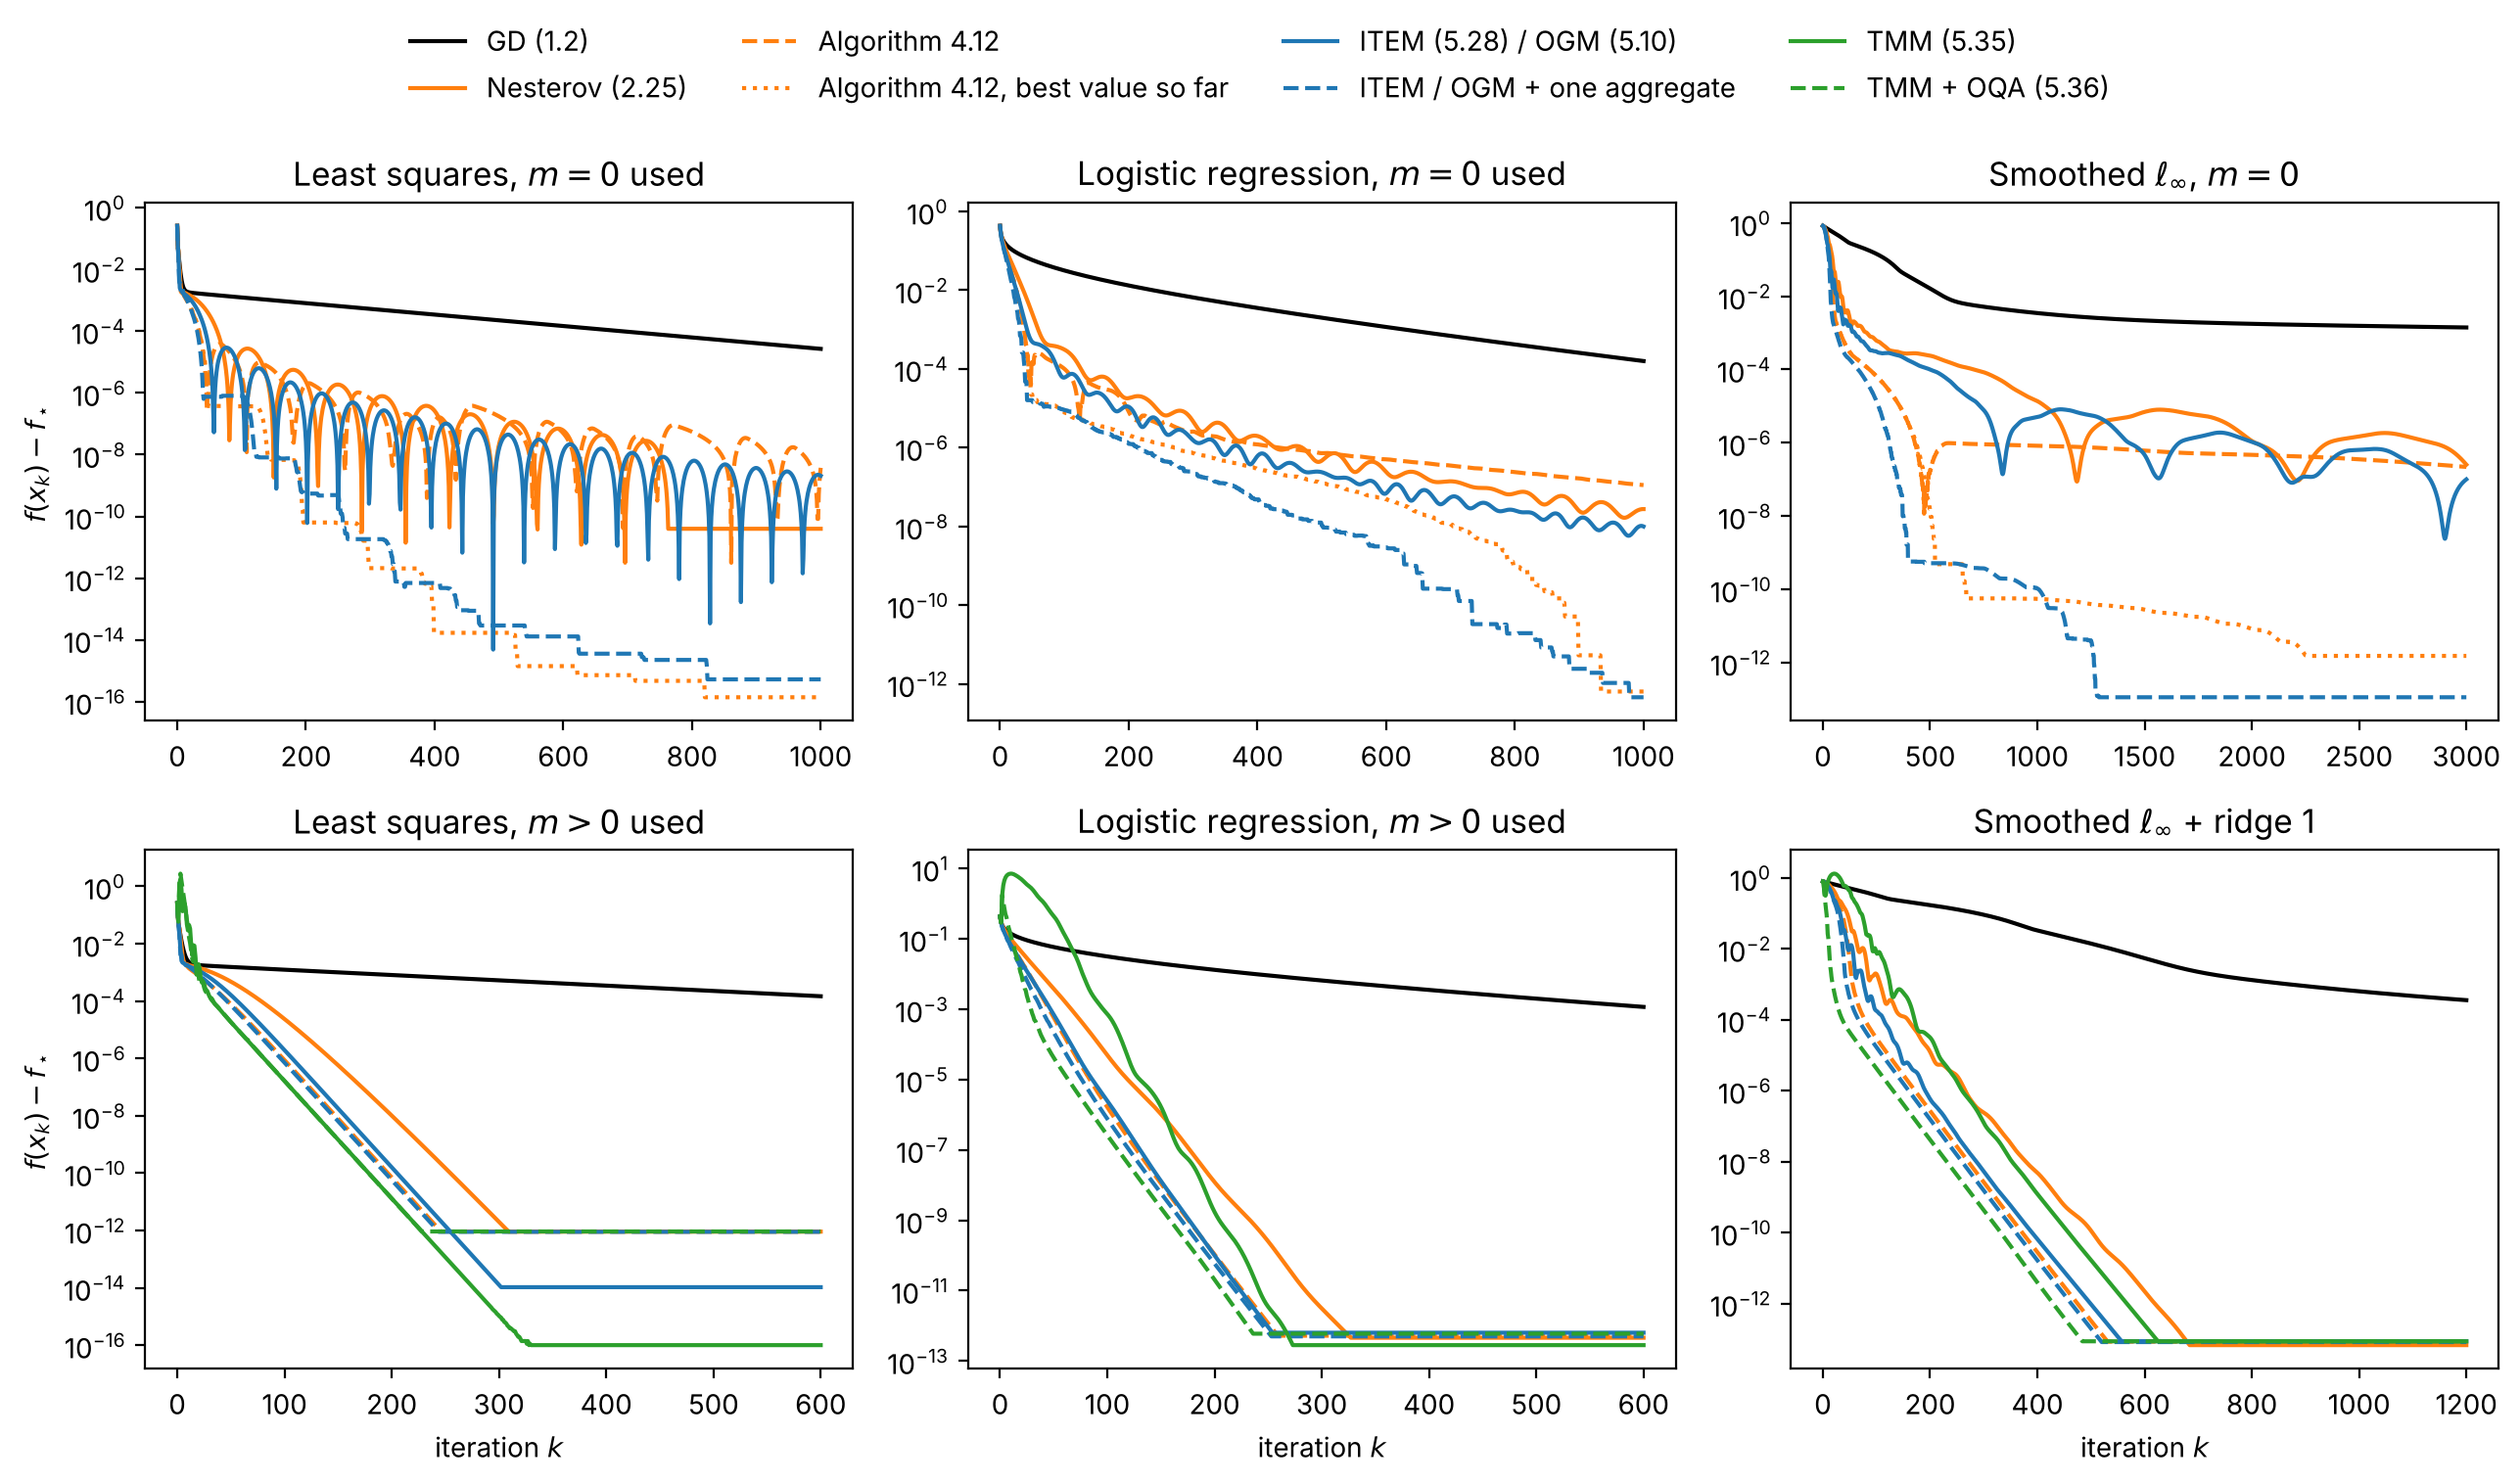

In [7]:
styles = {
    "gd": dict(color="black", label="GD (1.2)"),
    "nes": dict(color="tab:orange", label="Nesterov (2.25)"),
    "nes_mem": dict(color="tab:orange", ls="--", label="Algorithm 4.12"),
    "nes_best": dict(color="tab:orange", ls=":", label="Algorithm 4.12, best value so far"),
    "item": dict(color="tab:blue", label="ITEM (5.28) / OGM (5.10)"),
    "item_mem": dict(color="tab:blue", ls="--", label="ITEM / OGM + one aggregate"),
    "tmm": dict(color="tab:green", label="TMM (5.35)"),
    "oqa": dict(color="tab:green", ls="--", label="TMM + OQA (5.36)"),
}
fig, axes = plt.subplots(2, 3, figsize=(13, 7.6))
for ax, (name, (P, _)) in zip(axes.ravel(), runs.items()):
    R = results[name]; fs = R["f_star"]; n = P["n_iter"]
    for key, style in styles.items():
        if key not in R or (key == "nes_best" and R["m"] > 0): continue
        values = R[key] if key == "gd" else R[key]["f"]
        values = np.concatenate([values, np.full(n + 1 - len(values), values[-1])])       # last value repeated after the stop
        ax.semilogy(np.maximum(values - fs, 1e-16), **style)
    ax.set_title(name)
for ax in axes[1]: ax.set_xlabel("iteration $k$")
for ax in axes[:, 0]: ax.set_ylabel(r"$f(x_k) - f_\star$")
legend = {}
for ax in (axes[0, 0], axes[1, 0]):
    legend.update(dict(zip(ax.get_legend_handles_labels()[1], ax.get_legend_handles_labels()[0])))
legend = {style["label"]: legend[style["label"]] for style in styles.values()}
fig.legend(legend.values(), legend.keys(), loc="upper center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.92))
fig.savefig("memory_one_function_values.png", dpi=130)
plt.show()

Certificates of the triple momentum method ($m>0$): squared distance from the center $z_k$ of the ball to $x_\star$ (solid) and certified squared radius $R_k^2$ (dotted), with the weight of (5.35) and with optimal quadratic averaging (5.36). The curves are drawn while the certificate is above the round-off level.

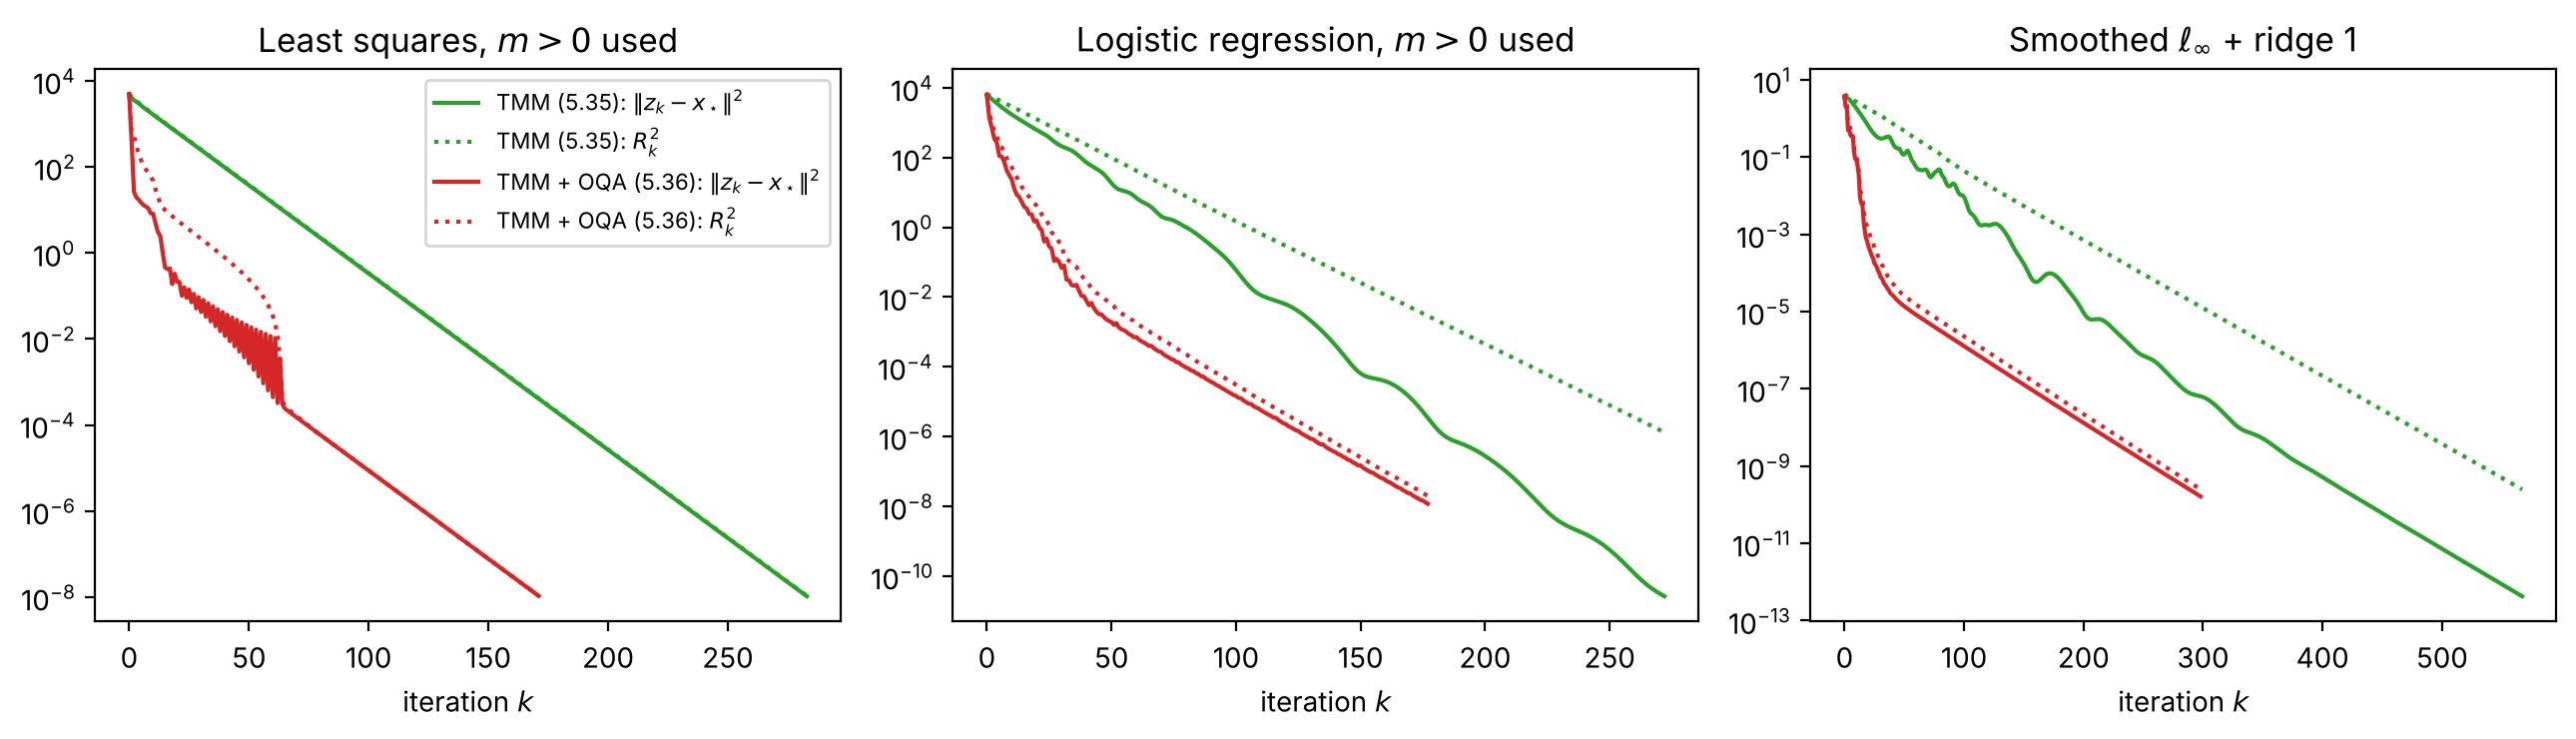

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (name, (P, _)) in zip(axes, list(runs.items())[3:]):
    R = results[name]
    for key, color, label in (("tmm", "tab:green", "TMM (5.35)"), ("oqa", "tab:red", "TMM + OQA (5.36)")):
        K = len(R[key]["contraction"]) + 1
        ax.semilogy(R[key]["dist2"][:K], color=color, label=label + r": $\|z_k-x_\star\|^2$")
        ax.semilogy(R[key]["R2"][:K], color=color, ls=":", label=label + r": $R_k^2$")
    ax.set_title(name); ax.set_xlabel("iteration $k$")
axes[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig("memory_one_certificates.png", dpi=130)
plt.show()

## Round-off of the weights with regularization

Least squares with the true $m$, ITEM with one aggregate, in double precision and in extended precision (`np.longdouble`, when the platform provides it). The table gives $(1+2qA_k)\|z_k-x_\star\|^2/\|x_0-x_\star\|^2-1$, which is nonpositive in exact arithmetic.

In [9]:
def least_squares_in(dtype):
    A, b = A_diabetes.astype(dtype), b_diabetes.astype(dtype)
    n = A.shape[0]
    f = lambda x: np.sum((A @ x - b) ** 2) / (2 * n)
    grad = lambda x: A.T @ (A @ x - b) / n
    H = A_diabetes.T @ A_diabetes / n
    ev = np.linalg.eigvalsh(H)
    x_star = np.linalg.solve(H, A_diabetes.T @ b_diabetes / n).astype(dtype)
    for _ in range(4):                                   # iterative refinement, with the residual in the working precision
        x_star = x_star - np.linalg.solve(H, grad(x_star).astype(float)).astype(dtype)
    return f, grad, np.zeros(A.shape[1], dtype=dtype), x_star, dtype(ev[-1]), dtype(ev[0])


rows = {}
for dtype in (np.float64, np.longdouble):
    f, grad, x0, x_star, L, m = least_squares_in(dtype)
    r = one_aggregate(f, grad, x0, x_star, L, m, 600, "item", upper="best")
    c = 1 + 2 * m / L * r["A"]
    excess = c * r["dist2"] / np.sum((x0 - x_star) ** 2) - 1
    column = {f"k = {k}": f"{float(excess[k]):+.1e}" for k in (100, 150, 180, 200, 220, 240)}
    column["1 + 2qA_k at k = 220"] = f"{float(c[220]):.1e}"
    rows[f"{dtype.__name__}, eps = {float(np.finfo(dtype).eps):.0e}"] = column
pd.DataFrame(rows)

,"float64, eps = 2e-16","longdouble, eps = 1e-19"
k = 100,-7.9e-03,-7.9e-03
k = 150,-8.2e-04,-8.2e-04
k = 180,-4.6e-04,-4.6e-04
k = 200,+1.9e-06,+1.4e-09
k = 220,+4.3e-06,+6.9e-09
k = 240,+6.9e-05,+4.8e-08
1 + 2qA_k at k = 220,1.4e+09,1.4e+09


**Reading the table.** On this problem the bound (5.30) with the realized weights is attained from $k\approx190$ on, so that nothing hides the round-off of the weights. The excess over the bound is about a thousand times smaller in extended precision ($10^{-9}$ instead of $2\cdot10^{-6}$ at $k=200$), as is the machine precision, and it grows with $1+2qA_k$ in both cases.